# ProtoStar — starter-model baseline

This notebook is the second step after `01_data_engineering.ipynb`. It uses the repository's existing starter Random Forest exactly as implemented in `code/starter_model.py`; it does not introduce a new model or write a submission.

**Goal:** understand the curated training data, run the official historical backtest, and establish the benchmark that any later experiment must beat.

## Guardrails

The data rule applies here: use weather data through 2018 only, and select models only with historical backtests. This notebook reads `data/annual_valid.csv` through the repository helper, which rejects weather rows after the cutoff.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 100)

# Find the repository root whether this runs in VS Code or from a notebook server.
for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if (candidate / "code" / "common.py").exists():
        PROJECT_ROOT = candidate
        break
else:
    raise FileNotFoundError("Open this notebook inside the ProtoStar-Challenge repository.")

CODE_DIR = PROJECT_ROOT / "code"
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

from common import CUTOFF_YEAR, FORECAST_YEARS, METRICS, load_valid_annual, wide
from starter_model import LAGS, backtest, forecast

print(f"Project root: {PROJECT_ROOT}")
print(f"Forecast cutoff: {CUTOFF_YEAR}")

Project root: C:\Users\achin\Desktop\protostar\ProtoStar-Challenge
Forecast cutoff: 2018


## Load the curated training data

`code/prepare_data.py` creates this file from the pinned official dataset. It keeps only records through 2018 and changes a metric to missing when the city-year violates the official 10-day missing-data rule.

If this cell cannot find the file, run `uv run python code/prepare_data.py` from the repository root first.

In [2]:
annual = load_valid_annual()
print(f"Loaded {len(annual):,} city-years for {annual['city_id'].nunique()} cities.")
print(f"Years: {annual['year'].min()}–{annual['year'].max()}")
annual.head()

Loaded 28,052 city-years for 210 cities.
Years: 1851–2018


,city_id,name,year,annual_avg_temp,total_precip_in,hottest_day_temp,cdd
0,USC00042863,Escondido,1894,NaN,NaN,NaN,NaN
1,USC00042863,Escondido,1895,62.34,NaN,102.0,1068.5
2,USC00042863,Escondido,1896,62.62,NaN,109.0,1095.0
3,USC00042863,Escondido,1897,60.09,NaN,111.0,931.0
4,USC00042863,Escondido,1898,59.98,NaN,110.0,953.0


## Data-engineering checkpoint

These are the exact model inputs after the preparation step. Missing target values are expected when the official coverage rule excludes a city-year metric; the model helpers handle them appropriately.

In [3]:
quality_summary = pd.DataFrame({
    "valid_values": annual[list(METRICS)].notna().sum(),
    "missing_values": annual[list(METRICS)].isna().sum(),
    "missing_pct": annual[list(METRICS)].isna().mean().mul(100),
    "min": annual[list(METRICS)].min(),
    "max": annual[list(METRICS)].max(),
}).round(2)
quality_summary

,valid_values,missing_values,missing_pct,min,max
annual_avg_temp,24583,3469,12.37,32.02,79.97
total_precip_in,24858,3194,11.39,0.03,114.03
hottest_day_temp,24583,3469,12.37,69.00,125.00
cdd,24583,3469,12.37,0.00,5538.75


In [4]:
# Inspect one metric in its city-by-year form—the representation used by the baseline.
METRIC_TO_INSPECT = "cdd"
metric_table = wide(annual, METRIC_TO_INSPECT)
print(f"{METRIC_TO_INSPECT}: {metric_table.shape[0]} cities × {metric_table.shape[1]} years")
metric_table.iloc[:5, -10:]

cdd: 210 cities × 168 years


year,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
city_id,,,,,,,,,,
USC00042863,NaN,NaN,1120.0,1395.0,1412.0,1988.5,1927.5,1705.5,1817.0,1784.55
USC00166584,2719.5,NaN,3268.0,3098.5,2297.0,2098.0,2525.5,2681.0,2775.5,3091.10
USC00280734,499.5,867.0,NaN,NaN,NaN,NaN,NaN,851.5,NaN,NaN
USC00286055,818.5,1338.5,1199.5,1171.0,1084.5,890.5,1223.5,1280.0,1066.5,1250.75
USC00356749,NaN,301.0,318.0,332.0,419.5,564.0,658.0,422.0,604.5,536.75


## Existing starter model

For each metric, the starter uses lag-1, lag-2, and lag-3 values for the same city as features. It trains one pooled `RandomForestRegressor` across cities, then forecasts recursively.

The historical evaluation below matches the repository pipeline: train through 2010 and predict 2011–2018. The only eligible scored rows are those meeting the coverage rule and with a valid 30-year baseline.

In [5]:
print(f"Starter-model lags: {LAGS}")
BACKTEST_LAST_TRAIN_YEAR = 2010
report = backtest(annual, last_year=BACKTEST_LAST_TRAIN_YEAR)
mae_table = report.pivot(index="model", columns="metric", values="mae").round(3)
mae_table

Starter-model lags: (1, 2, 3)


metric,annual_avg_temp,cdd,hottest_day_temp,total_precip_in
model,,,,
30_year_average,1.656,211.691,2.555,6.180
last_year_repeated,1.670,215.174,3.251,8.552
linear_trend,1.425,174.598,2.700,6.529
starter_rf_lags,1.814,197.350,3.273,7.568


In [6]:
baseline_mae = report.loc[report["model"].eq("30_year_average"), ["metric", "mae"]].set_index("metric")["mae"]
report = report.copy()
report["skill_vs_30_year_average"] = 1 - report["mae"] / report["metric"].map(baseline_mae)
score = 100 * report.groupby("model")["skill_vs_30_year_average"].mean().clip(lower=0)
display(report.sort_values(["metric", "mae"]).round(4))
print("Overall score (higher is better):")
score.sort_values(ascending=False).round(2)

,model,metric,mae,skill,skill_vs_30_year_average
3,linear_trend,annual_avg_temp,1.4255,0.1392,0.1392
2,30_year_average,annual_avg_temp,1.6560,0.0000,0.0000
1,last_year_repeated,annual_avg_temp,1.6704,-0.0087,-0.0087
0,starter_rf_lags,annual_avg_temp,1.8144,-0.0957,-0.0957
15,linear_trend,cdd,174.5978,0.1752,0.1752
12,starter_rf_lags,cdd,197.3504,0.0677,0.0677
14,30_year_average,cdd,211.6906,0.0000,0.0000
13,last_year_repeated,cdd,215.1745,-0.0165,-0.0165
10,30_year_average,hottest_day_temp,2.5550,0.0000,0.0000
11,linear_trend,hottest_day_temp,2.7004,-0.0569,-0.0569


Overall score (higher is better):


model
linear_trend          5.03
30_year_average       0.00
last_year_repeated    0.00
starter_rf_lags       0.00
Name: skill_vs_30_year_average, dtype: float64

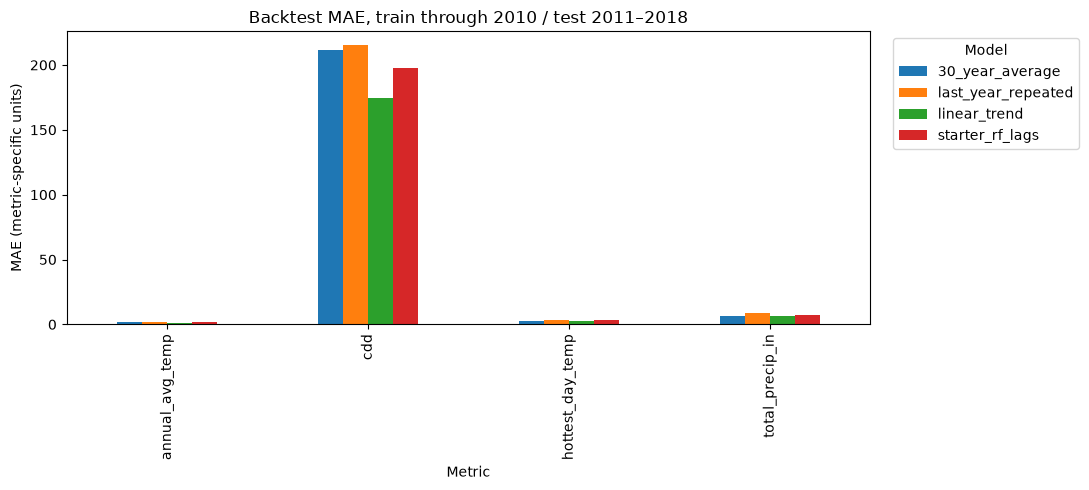

In [8]:
plot_table = report.pivot(index="metric", columns="model", values="mae")
ax = plot_table.plot(kind="bar", figsize=(11, 5))
ax.set_title("Backtest MAE, train through 2010 / test 2011–2018")
ax.set_ylabel("MAE (metric-specific units)")
ax.set_xlabel("Metric")
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

## Forecast preview (no file output)

This runs the already-implemented baseline with all data through 2018 and shows an in-memory preview. It deliberately does **not** write `submission.csv`; use `uv run python code/starter_model.py` when you intentionally want to regenerate the repository submission.

In [9]:
forecast_preview = {}
for metric in METRICS:
    forecast_preview[metric] = forecast(
        wide(annual, metric), last_year=CUTOFF_YEAR, years=FORECAST_YEARS
    )

city_id = forecast_preview["annual_avg_temp"].index[0]
pd.DataFrame({metric: values.loc[city_id] for metric, values in forecast_preview.items()})

,annual_avg_temp,total_precip_in,hottest_day_temp,cdd
2019,67.9150,14.6424,105.001000,1721.085
2020,68.5288,14.9999,102.470000,1738.580
2021,67.7988,14.6726,107.678643,1752.940
2022,67.2965,15.9554,104.049964,1772.595
2023,67.6507,14.6979,99.710833,1789.210
2024,67.3378,14.7075,102.147676,1769.910
2025,67.7194,12.0727,100.950804,1852.175


## Key insights

- The curated table has **28,052 city-years across 210 cities**. Roughly 11–12% of the values for each metric are unavailable after applying the official coverage rule, so missingness must remain part of every backtest.
- The lag-only Random Forest is not competitive: its overall challenge-style score is **0**. It beats the 30-year average only for CDD (`197.35` versus `211.69` MAE) and performs worse for the other three metrics.
- The linear trend is the strongest overall reference, scoring **5.03**, and has the lowest MAE for average temperature (`1.43 °F`) and CDD (`174.60 °F-days`).
- The 30-year average remains best for precipitation (`6.18 in`) and hottest-day temperature (`2.56 °F`). These targets contain substantial year-to-year noise that the lag-based RF amplifies.
- A single model need not be best for every metric. The results support a metric-specific strategy: more trend for average temperature/CDD and more historical averaging for precipitation/hottest day.

## What comes next

Test a simple blend of the 30-year average and linear trend, selecting its weights on an earlier historical period and evaluating the frozen choice on 2011–2018. Any successful method must eventually be promoted into `code/`; the notebook itself is not the submission pipeline.